# Process Model Improvement

In [11]:
# Filter data: only start events
import pandas as pd

from preprocessing import load_raw_log

pd.set_option('display.max_colwidth', None)

raw = load_raw_log()

# A_ and O_ events only have a 'complete' event, so they are kept. W_ events are reduced to their 'start' event
df_start = raw[(raw['EventOrigin'] != 'Workflow') | (raw['lifecycle:transition'] == 'start')]

print(f"Original log: {len(raw):,} events")
print(f"Start events: {len(df_start):,} events, {df_start['case:concept:name'].nunique():,} cases")

Original log: 1,202,267 events
Start events: 561,671 events, 31,509 cases


In [12]:
# Filter data: Group by variants and focus on the most common variants:
case_variants = df_start.groupby('case:concept:name')['concept:name'].agg(' > '.join)

variants = case_variants.value_counts().rename_axis('variant').reset_index(name='cases')
variants['share'] = variants['cases'] / variants['cases'].sum()
variants['cumulative share'] = variants['share'].cumsum()

print(f"{len(variants):,} variants")
variants.head(60)

4,047 variants


,variant,cases,share,cumulative share
0,A_Create Application > A_Submitted > A_Concept > W_Complete application > A_Accepted > O_Create Offer > O_Created > O_Sent (mail and online) > W_Call after offers > A_Complete > A_Cancelled > O_Cancelled,3656,0.116030,0.116030
1,A_Create Application > A_Submitted > A_Concept > W_Complete application > A_Accepted > O_Create Offer > O_Created > O_Sent (mail and online) > W_Call after offers > A_Complete > W_Validate application > A_Validating > O_Returned > W_Call incomplete files > A_Incomplete > W_Validate application > A_Validating > O_Accepted > A_Pending,1454,0.046146,0.162176
2,A_Create Application > A_Submitted > A_Concept > W_Complete application > A_Accepted > O_Create Offer > O_Created > O_Sent (mail and online) > W_Call after offers > A_Complete > W_Validate application > A_Validating > O_Returned > O_Accepted > A_Pending,1367,0.043384,0.205560
3,A_Create Application > W_Complete application > A_Concept > A_Accepted > O_Create Offer > O_Created > O_Sent (mail and online) > W_Call after offers > A_Complete > A_Cancelled > O_Cancelled,1354,0.042972,0.248532
4,A_Create Application > A_Concept > W_Complete application > A_Accepted > O_Create Offer > O_Created > O_Sent (mail and online) > W_Call after offers > A_Complete > W_Validate application > A_Validating > O_Returned > O_Accepted > A_Pending,1172,0.037196,0.285728
5,A_Create Application > A_Submitted > A_Concept > W_Complete application > A_Accepted > O_Create Offer > O_Created > O_Sent (mail and online) > W_Call after offers > A_Complete > W_Validate application > A_Validating > O_Returned > W_Call incomplete files > A_Incomplete > O_Accepted > A_Pending,902,0.028627,0.314355
6,A_Create Application > A_Submitted > W_Handle leads > W_Complete application > A_Concept > A_Accepted > O_Create Offer > O_Created > O_Sent (mail and online) > W_Call after offers > A_Complete > A_Cancelled > O_Cancelled,885,0.028087,0.342442
7,A_Create Application > W_Complete application > A_Concept > A_Accepted > O_Create Offer > O_Created > O_Sent (mail and online) > W_Call after offers > A_Complete > W_Validate application > A_Validating > O_Returned > W_Call incomplete files > A_Incomplete > W_Validate application > A_Validating > O_Accepted > A_Pending,776,0.024628,0.367070
8,A_Create Application > A_Submitted > A_Concept > W_Complete application > A_Accepted > O_Create Offer > O_Created > O_Sent (mail and online) > W_Call after offers > A_Complete > W_Validate application > A_Validating > O_Returned > A_Denied > O_Refused,719,0.022819,0.389889
9,A_Create Application > W_Complete application > A_Concept > A_Accepted > O_Create Offer > O_Created > O_Sent (mail and online) > W_Call after offers > A_Complete > W_Validate application > A_Validating > O_Returned > O_Accepted > A_Pending,690,0.021899,0.411787


In [13]:
# Discard the variants with a low share
MIN_SHARE = 0.003

kept_variants = variants[variants['share'] >= MIN_SHARE]
kept_cases = case_variants[case_variants.isin(kept_variants['variant'])].index
df_kept = df_start[df_start['case:concept:name'].isin(kept_cases)]

print(f"Kept {len(kept_variants)} of {len(variants):,} variants")
print(f"Kept {len(kept_cases):,} of {len(case_variants):,} cases ({len(kept_cases) / len(case_variants):.1%})")

Kept 42 of 4,047 variants
Kept 20,626 of 31,509 cases (65.5%)


In [14]:
# Filter activities: How often did they occur?
activity_counts = pd.DataFrame({
    'events': df_kept['concept:name'].value_counts(),
    'cases': df_kept.groupby('concept:name')['case:concept:name'].nunique(),
})
activity_counts['share of cases'] = (activity_counts['cases'] / len(kept_cases)).round(3)
activity_counts.sort_values('cases', ascending=False)

,events,cases,share of cases
concept:name,,,
A_Accepted,20626,20626,1.000
O_Create Offer,22428,20626,1.000
A_Complete,20626,20626,1.000
A_Concept,20626,20626,1.000
A_Create Application,20626,20626,1.000
W_Call after offers,20626,20626,1.000
O_Sent (mail and online),22428,20626,1.000
O_Created,22428,20626,1.000
W_Complete application,19686,19686,0.954


In [33]:
# Inspect variants after an activity: which activities follow it, and in which order?
def variants_after(log, activity, steps=3):
    # Every occurrence of the activity counts, steps=None shows the rest of the case
    sequences = []
    for trace in log.groupby('case:concept:name')['concept:name'].agg(list):
        for i, name in enumerate(trace):
            if name == activity:
                following = trace[i + 1:] if steps is None else trace[i + 1:i + 1 + steps]
                sequences.append(' > '.join(following) or '(end of case)')
    table = pd.Series(sequences).value_counts().rename_axis(f'after {activity}').reset_index(name='occurrences')
    table['share'] = (table['occurrences'] / len(sequences)).round(3)
    return table


variants_after(df_kept, 'O_Sent (mail and online)', steps=3)

,after O_Sent (mail and online),occurrences,share
0,W_Call after offers > A_Complete > W_Validate application,12267,0.547
1,W_Call after offers > A_Complete > A_Cancelled,7518,0.335
2,O_Sent (mail and online) > W_Call after offers > A_Complete,961,0.043
3,W_Call after offers > A_Complete > O_Create Offer,841,0.037
4,A_Cancelled > O_Cancelled > O_Cancelled,471,0.021
5,W_Validate application > A_Validating > O_Returned,370,0.016


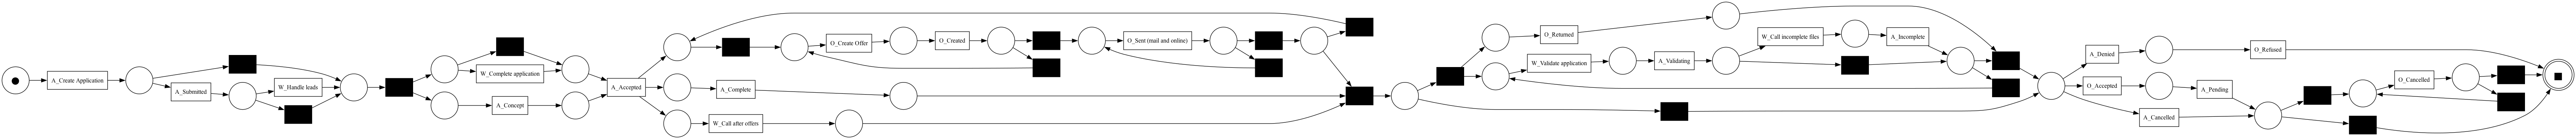

In [15]:
# Process model: Inductive Miner on the filtered data set
import pm4py

net, im, fm = pm4py.discover_petri_net_inductive(df_kept)
pm4py.view_petri_net(net, im, fm)

In [16]:
# Save the model as BPMN and evaluate the saved BPMN
from evaluation import evaluate_model

BPMN_PATH = '../output/03_inductive_miner.bpmn'

bpmn = pm4py.convert_to_bpmn(net, im, fm)  # pyright: ignore[reportArgumentType]  (pm4py's type hint is wrong)
pm4py.write_bpmn(bpmn, BPMN_PATH)
print(f'Saved {BPMN_PATH}')

bpmn_model = pm4py.convert_to_petri_net(pm4py.read_bpmn(BPMN_PATH))
pd.DataFrame({
    'filtered cases (df_kept)': evaluate_model(df_kept, bpmn_model),
    'all cases (df_start)': evaluate_model(df_start, bpmn_model),
}).round(3)

Saved ../output/03_inductive_miner.bpmn


replaying log with TBR, completed traces :: 100%|██████████| 4047/4047 [00:04<00:00, 888.76it/s] 


,filtered cases (df_kept),all cases (df_start)
Fitness,1.000,0.992
Perfect_Fit_Share,1.000,0.819
Precision,0.519,0.655
Generalization,0.988,0.992
Simplicity,0.724,0.724
Simplicity_NodeDegree,5.000,5.000
Simplicity_Depth,4.000,4.000
Silent_Share,0.522,0.522


In [34]:
BPMN_PATH = '../data/04_process_model.bpmn'

bpmn = pm4py.convert_to_bpmn(net, im, fm)  # pyright: ignore[reportArgumentType]  (pm4py's type hint is wrong)
pm4py.write_bpmn(bpmn, BPMN_PATH)
print(f'Saved {BPMN_PATH}')

bpmn_model = pm4py.convert_to_petri_net(pm4py.read_bpmn(BPMN_PATH))
pd.DataFrame({
    'filtered cases (df_kept)': evaluate_model(df_kept, bpmn_model),
    'all cases (df_start)': evaluate_model(df_start, bpmn_model),
}).round(3)

Saved ../data/04_process_model.bpmn


replaying log with TBR, completed traces :: 100%|██████████| 4047/4047 [00:04<00:00, 968.47it/s] 


,filtered cases (df_kept),all cases (df_start)
Fitness,1.000,0.992
Perfect_Fit_Share,1.000,0.819
Precision,0.519,0.655
Generalization,0.988,0.992
Simplicity,0.724,0.724
Simplicity_NodeDegree,5.000,5.000
Simplicity_Depth,4.000,4.000
Silent_Share,0.522,0.522
